======================================================================
CAPSTONE PROJECT 2 - ONLINE RETAIL CUSTOMER INSIGHTS AND SEGMENTATION
======================================================================


#  Problem Statement



The online retail store wants evidence-based insight into customer purchase patterns so that it can better understand
customer purchasing history and segment customers according to behavior.

The project therefore combines
transaction-level EDA with customer-level RFM analysis and clustering.

#  Project Objective



The objectives are to clean the transaction data, identify the most important customer/product/geographic patterns,

calculate customer-level purchase metrics, build RFM features, select a suitable number of clusters and produceactionable customer segments.

# Importing libraries

In [2]:

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


---


# Loading the data

---


In [3]:
online = pd.read_csv('OnlineRetail.csv', encoding='latin1')

online.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


#  Converting " Invoice Date and Invoice Number " to Correct Data Types

---


In [4]:

online['InvoiceDate'] = pd.to_datetime(online['InvoiceDate'], errors='coerce')
online['InvoiceNo'] = online['InvoiceNo'].astype(str)

# Basic Data Inspection

In [5]:
print('Raw shape:', online.shape)
print('Missing values:\n', online.isna().sum())
print('Duplicate rows:', online.duplicated().sum())
print('Date range:', online['InvoiceDate'].min(), 'to', online['InvoiceDate'].max())

Raw shape: (541909, 8)
Missing values:
 InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64
Duplicate rows: 5268
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


# Checking Column  Data types, Missing Values and unique values in a dataframe

In [6]:
df = pd.DataFrame({
    'Column_dtype_as_text': online.dtypes.astype(str),
    'Missing_values_each_column': online.isna().sum(),
    'Percentage of missing values': online.isna().mean() * 100,
    'Unique_values_each_column': online.nunique()
})

df


,Column_dtype_as_text,Missing_values_each_column,Percentage of missing values,Unique_values_each_column
InvoiceNo,object,0,0.000000,25900
StockCode,object,0,0.000000,4070
Description,object,1454,0.268311,4223
Quantity,int64,0,0.000000,722
InvoiceDate,datetime64[ns],0,0.000000,23260
UnitPrice,float64,0,0.000000,1630
CustomerID,float64,135080,24.926694,4372
Country,object,0,0.000000,38


# Cleaning the Online Retail Dataframe

In [7]:
clean = online[
    ~online['InvoiceNo'].str.startswith('C')
    & (online['Quantity'] > 0)
    & (online['UnitPrice'] > 0)
    & online['CustomerID'].notna()
].copy()


clean['CustomerID'] = clean['CustomerID'].astype(int)
clean['Revenue'] = clean['Quantity'] * clean['UnitPrice']

# Checking the Result of Data Cleaning

In [8]:

print('Clean shape:', clean.shape)
print('Rows removed:', len(online) - len(clean))

Clean shape: (397884, 9)
Rows removed: 144025


#  Data Description

The uploaded file contains 541,909 rows before cleaning. 

This differs from the 387,961 rows stated in the assignment text; 

The complete uploaded file was analyzed. 

After cleaning, 397,884 transaction rows remained.

# Creating Customers Summary

In [9]:
customer_summary = clean.groupby('CustomerID').agg(
    Different_Orders_Placed=('InvoiceNo', 'nunique'),
    Total_Units_Bought=('Quantity', 'sum'),
    Sales_value=('Revenue', 'sum'),
    Different_Products_Bought=('StockCode', 'nunique')
).reset_index()

customer_summary

,CustomerID,Different_Orders_Placed,Total_Units_Bought,Sales_value,Different_Products_Bought
0,12346,1,74215,77183.60,1
1,12347,7,2458,4310.00,103
2,12348,4,2341,1797.24,22
3,12349,1,631,1757.55,73
4,12350,1,197,334.40,17
...,...,...,...,...,...
4333,18280,1,45,180.60,10
4334,18281,1,54,80.82,7
4335,18282,2,103,178.05,12
4336,18283,16,1397,2094.88,263


# Creating Country & Product Summary

In [10]:
country_summary = clean.groupby('Country')['Revenue'].sum().sort_values(ascending=False)
product_summary = clean.groupby('Description')['Revenue'].sum().sort_values(ascending=False)

# Business/purchasing insights:

In [11]:
print('Total Revenue:', clean['Revenue'].sum())
print('Total Units sold:', clean['Quantity'].sum())
print('Unique Customers:', clean['CustomerID'].nunique())
print('Orders given:', clean['InvoiceNo'].nunique())
print('Products sold:', clean['StockCode'].nunique())
print('Unique Countries:', clean['Country'].nunique())
print('Average revenue per Order:',clean.groupby('InvoiceNo')['Revenue'].sum().mean())
print('Percentage of customers with more than one order:',(customer_summary['Different_Orders_Placed'] > 1).mean() * 100)
print('Strongest-performing Country::', country_summary.index[0])
print('Best-performing Product:', product_summary.index[0])


Total Revenue: 8911407.904
Total Units sold: 5167812
Unique Customers: 4338
Orders given: 18532
Products sold: 3665
Unique Countries: 37
Average revenue per Order: 480.8659563997409
Percentage of customers with more than one order: 65.58321807284463
Strongest-performing Country:: United Kingdom
Best-performing Product: PAPER CRAFT , LITTLE BIRDIE


# RFM customer segmentation

In [12]:
Fixed_Refrence_Date = clean['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = clean.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (Fixed_Refrence_Date - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('Revenue', 'sum')
).reset_index()

rfm 

,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40
...,...,...,...,...
4333,18280,278,1,180.60
4334,18281,181,1,80.82
4335,18282,8,2,178.05
4336,18283,4,16,2094.88


#  Data Pre-processing Steps and Inspiration

1

Converted InvoiceDate into date format so I could work with the purchase dates properly.

2

Removed cancelled orders where InvoiceNo starts with C.

3 

Removed records where Quantity or Price was zero or negative 
because I only wanted to analyze actual sales.

4 

Removed records where CustomerID was missing 
because customer information is required for customer segmentation.

5 

Created a new Revenue column by multiplying Quantity by Price.

6 
Grouped the transactions customer-wise and created RFM values to understand each customer's purchasing behavior.

# Assumptions


1 

I considered only completed purchases 
with a positive quantity and price for the customer analysis.

2 

Recency is the " number of days since the last purchase ".

3 

Frequency means the " total number of different orders placed by a customer."

4 

Monetary means the total amount spent by a customer, 

calculated as Quantity × UnitPrice.

5 

The customer groups created by clustering 
show similar purchasing behavior. 



# 9. Final K-Means segmentation

In [13]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

#  Log Transformation of RFM Data

In [14]:
X = np.log1p(rfm[['Recency', 'Frequency', 'Monetary']])

# Apply K-Means Clustering and Finding the Best Number of Clusters and Silhouette Score 

 This code tests different values of k from 2 to 6 using the Silhouette Score and selects the k that gives the best clustering quality.

In [15]:
Silhouette_scores = {}

for k in range(2, 7):
    model = Pipeline([
        ('scaler', StandardScaler()),
        ('kmeans', KMeans(n_clusters=k, random_state=42, n_init=10))
    ])
    
    labels = model.fit_predict(X)
    Silhouette_scores[k] = silhouette_score(
        model.named_steps['scaler'].transform(X),
        labels
    )

best_k = max(Silhouette_scores, key=Silhouette_scores.get)

print(f'Highest silhouette score: {Silhouette_scores[best_k]:.4f} at K={best_k}')

Highest silhouette score: 0.4329 at K=2


#  Choosing the Algorithm for the Project



1

I selected K-Means clustering to divide customers into different groups based on their purchasing behavior. 

For this, I used three RFM values: Recency, Frequency, and Monetary value. 

3 

I applied log1p to reduce the effect of very high values 
and then standardized the data before applying K-Means. 

4

I tested different numbers of clusters from 2 to 6 
and used the " silhouette score to choose the number of clusters "
that gave the best result.

#  Model Evaluation and Techniques



The highest silhouette score is 0.4329 at K=2. 
That K was selected for the final saved segmentation model.

# Customer segmentation insight:

In [16]:
model = Pipeline([
    ('scaler', StandardScaler()),
    ('kmeans', KMeans(
        n_clusters=best_k,
        random_state=42,
        n_init=10
    ))
])

rfm['Segment'] = model.fit_predict(X)

# RFM Segment Mapping

In [17]:
rfm['Segment'] = rfm['Segment'].map({
    0: 'Low-Value Customer',
    1: 'High-Value Customer'
})

In [18]:
print('CUSTOMER SEMENTATION PROFILE')
print(rfm.groupby('Segment')[['Recency', 'Frequency', 'Monetary']].mean())

CUSTOMER SEMENTATION PROFILE
                        Recency  Frequency     Monetary
Segment                                                
High-Value Customer   25.883623   8.440312  4548.258417
Low-Value Customer   134.135155   1.670535   497.739095


# PERFORMING VISUALISATION

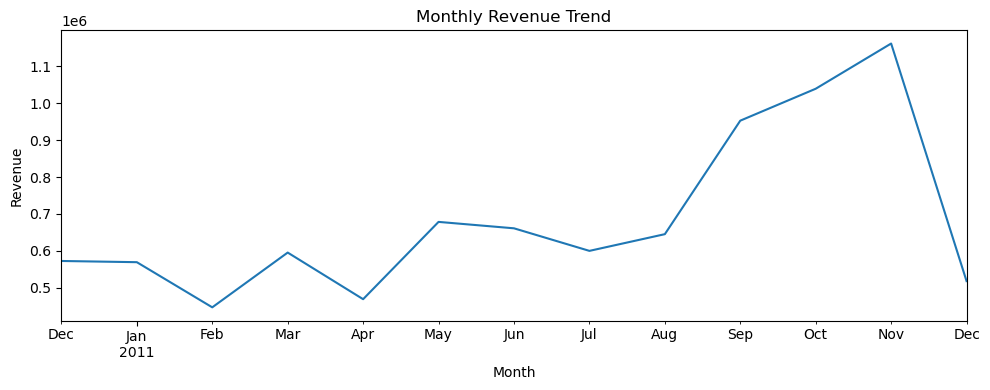

In [19]:
# 1. Monthly Revenue Trend

monthly = clean.groupby(
    clean['InvoiceDate'].dt.to_period('M')
)['Revenue'].sum()

monthly.plot(kind='line', figsize=(10, 4))
plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.tight_layout()
plt.show()

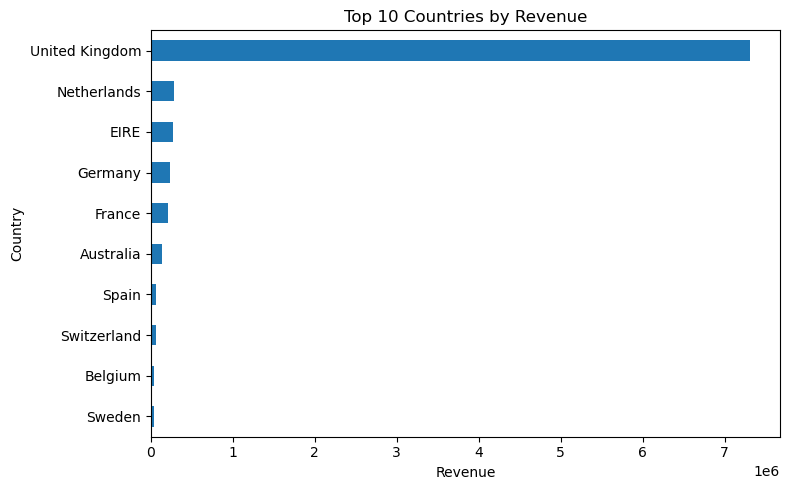

In [20]:
# 2. Top 10 Countries by Revenue
country_summary.head(10).sort_values().plot(
    kind='barh', figsize=(8, 5)
)

plt.title('Top 10 Countries by Revenue')
plt.xlabel('Revenue')
plt.tight_layout()
plt.show()

# Customer Segment Distribution

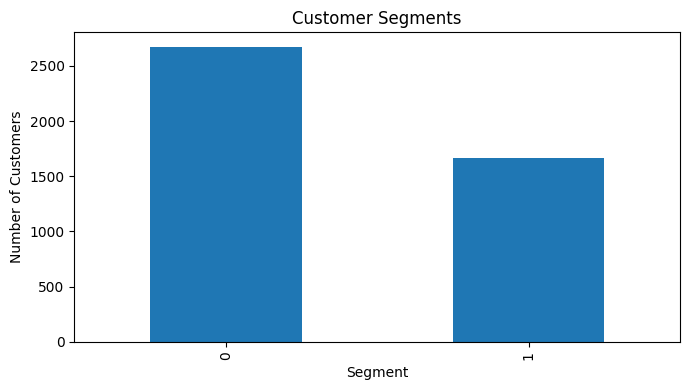

In [36]:

rfm['Segment'].value_counts().sort_index().plot(
    kind='bar', figsize=(7, 4)
)

plt.title('Customer Segments')
plt.xlabel('Segment')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

# 10. Saving the model

In [21]:
joblib.dump(model, 'online_retail_customer_segmentation.joblib')


['online_retail_customer_segmentation.joblib']

# Save the important final result

In [22]:
rfm.to_csv('online_retail_customer_segments.csv', index=False)

#  Motivation and Reasons for Choosing the Algorithm



1 RFM is easy to understand because it tells us three simple things about a customer: 

when they last purchased, 
how often they purchase, 
and how much they spend.

2 K-Means is simple to explain and gives every customer a clear cluster assignment.

3 Log transformation and scaling prevent high-spending customers from dominating the distance calculation.

# Inferences from the project



1 

The United Kingdom is the largest revenue market/country 

2 

The highest-revenue product in the cleaned data is
'PAPER CRAFT , LITTLE BIRDIE', 

3 

The cleaned transaction base contains 4,338 customers, 18,532 orders, 3,665 distinct products and 37 countries. 

4 
Total revenue in the cleaned analysis is 8,911,407.90; 
average order value is 480.87; 
and approximately 65.58% of customers placed more than one order.

5 

Interpretation: 

the High-Value Active cluster OR  segment 1
has much lower recency and much higher purchase frequency 


#  Future Possibilities of the Project



Based on the project created,
In the future, I can study customers based on :

the products they buy, 
their average order size, 
discount usage, 
and how often they come back to purchase.

We can also build models to identify customers :

who may stop purchasing, 
to predict when they may buy again, 
and estimate their future value 

#  Conclusion:



The project helped me understand customer purchasing patterns 
and identify useful business insights. 

I used RFM analysis and K-Means clustering to divide customers into different groups based on their purchasing behavior.
.



#  References and Source Files


• OnlineRetail.csv - uploaded online-retail transaction dataset.


### Deployment artifact
This cell saves the trained customer-segmentation pipeline as `model.pkl` for Streamlit/REST deployment.

In [ ]:
# Deployment export: preserve the original trained `model` and save an additional standard filename.
joblib.dump(model, 'model.pkl')
print('Saved model.pkl')
